# 03 — Réception télémétrie (10 secondes)

Connexion UDP 2345 **lecture seule**. Affiche les champs réellement envoyés et sauvegarde un CSV de diagnostic. Un seul client UDP à la fois.

In [5]:
from pathlib import Path
import sys
CWD=Path.cwd().resolve()
REPO=next((p for p in [CWD,*CWD.parents] if (p/'assetto_corsa_gym'/'assetto_corsa_gym'/'AssettoCorsaEnv').is_dir()),None)
if REPO is None:
    raise FileNotFoundError('Ouvre le depot IA_projet_Ouarti_ds_github dans VS Code : son dossier assetto_corsa_gym doit exister.')
PROJECT=REPO/'Code'
if not PROJECT.is_dir():
    raise FileNotFoundError('Dossier Code absent : extraire Code a la racine du depot.')
GYM_ROOT=REPO/'assetto_corsa_gym'/'assetto_corsa_gym'
print('Depot :',REPO)
print('Notebooks :',PROJECT)
print('Python :',sys.version.split()[0],sys.executable)


Depot : C:\Users\elkat\Documents\Github\IA_projet_Ouarti_ds_github
Notebooks : C:\Users\elkat\Documents\Github\IA_projet_Ouarti_ds_github\Code
Python : 3.9.13 c:\Users\elkat\AppData\Local\Programs\Python\Python39\python.exe


In [6]:
import socket, json, ast, time
HOST='127.0.0.1'
PORT_UDP=2345
PORT_TCP=2347

def management(message,timeout=3):
    with socket.create_connection((HOST,PORT_TCP),timeout=timeout) as s:
        s.settimeout(timeout);s.sendall(message.encode('ascii'))
        data=b''
        end=time.monotonic()+timeout
        while time.monotonic()<end and len(data)<1024*1024:
            try:chunk=s.recv(65536)
            except socket.timeout:break
            if not chunk:break
            data+=chunk
            try:return json.loads(data)
            except (json.JSONDecodeError, UnicodeDecodeError):pass
            try:return ast.literal_eval(data.decode('utf8'))
            except (ValueError,SyntaxError,UnicodeDecodeError):pass
        if data:
            raise RuntimeError('Reponse TCP incomplete : '+repr(data[:160]))
    raise RuntimeError('Pas de reponse sur le port management')

def open_telemetry(timeout=4):
    s=socket.socket(socket.AF_INET,socket.SOCK_DGRAM);s.settimeout(.4)
    s.connect((HOST,PORT_UDP))
    end=time.monotonic()+timeout
    while time.monotonic()<end:
        s.send(b'connect')
        try:response=s.recv(2**18)
        except socket.timeout:continue
        if response==b'identified':return s
    s.close()
    raise TimeoutError('Pas de confirmation UDP sur 2345 : verifier jeu en piste et plugin sensors_par.')

def next_packet(s,timeout=3):
    end=time.monotonic()+timeout
    while time.monotonic()<end:
        try:message=s.recv(2**18)
        except socket.timeout:continue
        if message==b'disconnect':raise ConnectionError('Le jeu a ferme le flux UDP')
        if message==b'identified':continue
        raw=json.loads(message)
        if not isinstance(raw,dict):continue
        raw['_capture_wall_time']=time.time()
        return raw
    raise TimeoutError('Aucun echantillon recu.')

def close_telemetry(s):
    if s is not None:
        try:s.send(b'disconnect')
        except OSError:pass
        s.close()


In [7]:
import pandas as pd
DUREE=10
DONNEES=[]
connection=None
try:
    connection=open_telemetry()
    debut=time.monotonic()
    while time.monotonic()-debut<DUREE:
        item=next_packet(connection,timeout=3)
        DONNEES.append(item)
        if len(DONNEES)==1:
            print('Champs recus :',sorted(item.keys()))
finally:
    close_telemetry(connection)
if not DONNEES:raise RuntimeError('Aucune mesure recue.')
df=pd.DataFrame(DONNEES)
filename=PROJECT/'reports'/'telemetrie_test.csv'
filename.parent.mkdir(parents=True,exist_ok=True)
df.to_csv(filename,index=False)
print('Nombre echantillons :',len(df))
print('Sauvegarde :',filename)
display(df.head())


ConnectionResetError: [WinError 10054] Une connexion existante a dû être fermée par l’hôte distant

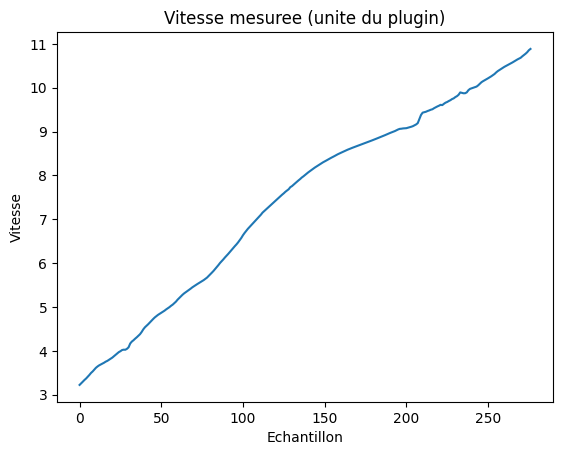

In [ ]:
import matplotlib.pyplot as plt
if 'speed' in df:
    ax=df['speed'].astype(float).plot(title='Vitesse mesuree (unite du plugin)')
    ax.set_xlabel('Echantillon');ax.set_ylabel('Vitesse')
    plt.show()
else:
    print('Champ speed absent : examiner les colonnes affichees.')


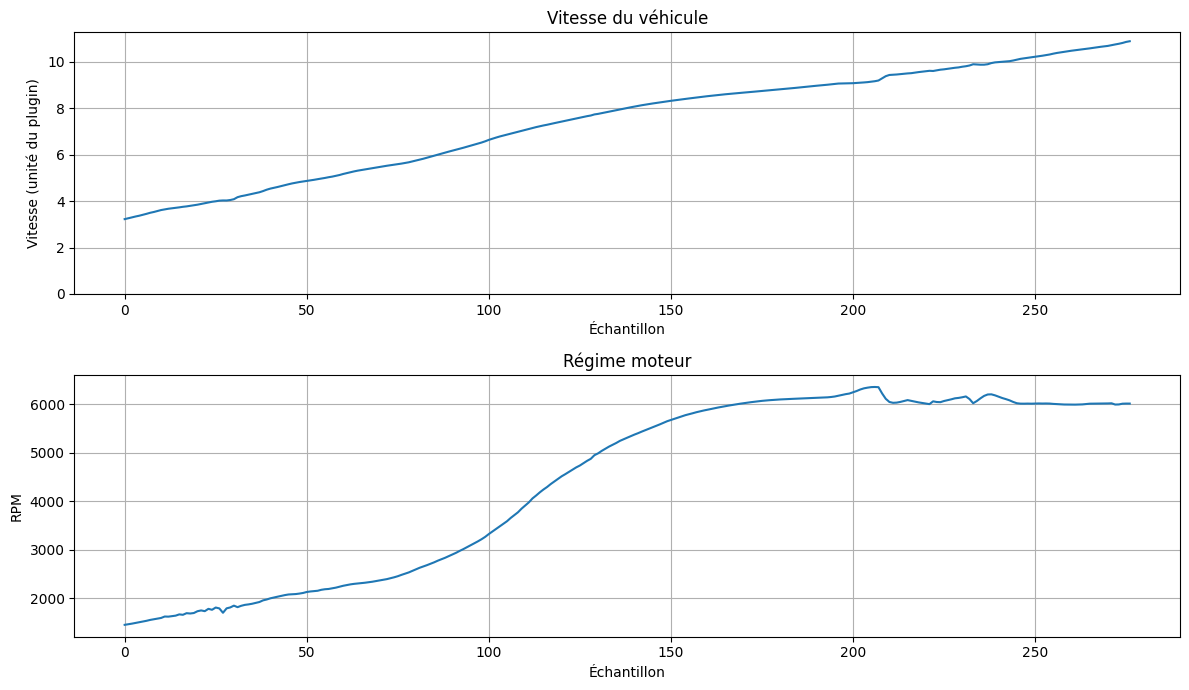

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

# Vitesse mesurée
axes[0].plot(df["speed"].astype(float))
axes[0].set_title("Vitesse du véhicule")
axes[0].set_xlabel("Échantillon")
axes[0].set_ylabel("Vitesse (unité du plugin)")
axes[0].set_ylim(bottom=0)
axes[0].grid(True)

# Régime moteur
axes[1].plot(df["RPM"].astype(float))
axes[1].set_title("Régime moteur")
axes[1].set_xlabel("Échantillon")
axes[1].set_ylabel("RPM")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

temps = pd.to_datetime(
    df["_capture_wall_time"],
    unit="s",
    utc=True
).dt.tz_convert("Europe/Paris")

print("Début :", temps.iloc[0])
print("Fin   :", temps.iloc[-1])
print("Durée :", (temps.iloc[-1] - temps.iloc[0]).total_seconds(), "secondes")

Début : 2026-11-11 22:02:38.548924928+01:00
Fin   : 2026-11-11 22:02:48.437574912+01:00
Durée : 9.888649 secondes


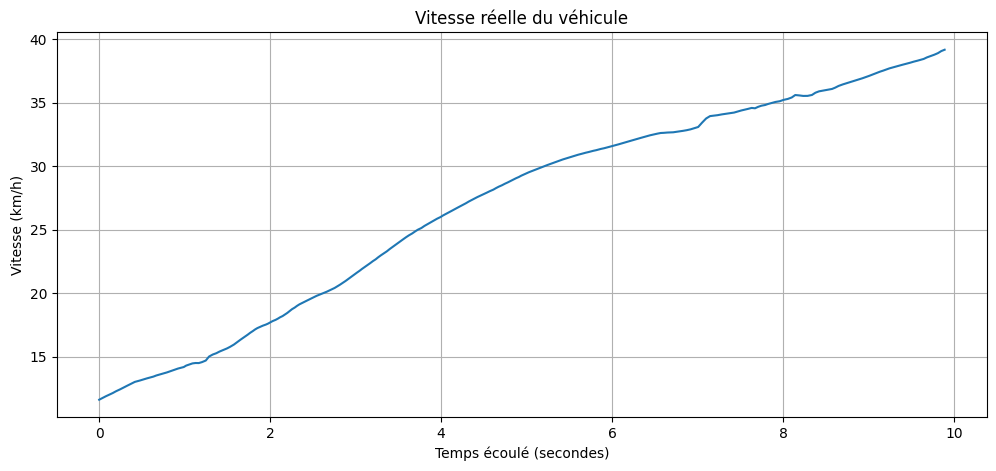

In [ ]:
import matplotlib.pyplot as plt

vitesse_kmh = df["speed"].astype(float) * 3.6
temps_s = df["_capture_wall_time"] - df["_capture_wall_time"].iloc[0]

plt.figure(figsize=(12, 5))
plt.plot(temps_s, vitesse_kmh)

plt.title("Vitesse réelle du véhicule")
plt.xlabel("Temps écoulé (secondes)")
plt.ylabel("Vitesse (km/h)")
plt.grid(True)

plt.show()